# Week 10-11: Clustering Phishing Websites using K-Means , DB Scan and Hirearchical clustering


This notebook applies K-Means, DBSCAN, and hierarchical clustering to the phishing website dataset. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    accuracy_score,
    confusion_matrix,
)
from scipy.cluster.hierarchy import linkage, dendrogram


In [2]:
df = pd.read_csv('./dataset/web_page_dataset_phishing.csv')
print('Dataset shape:', df.shape)
print(df['status'].value_counts())


Dataset shape: (11430, 89)
status
legitimate    5715
phishing      5715
Name: count, dtype: int64


In [3]:
# Convert the target for class metrics.
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})

# URLs are unique and should not be used as numeric model features.
X = df.drop(columns=['url', 'status']).select_dtypes(include='number')
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training rows:', X_train.shape[0])
print('Test rows:', X_test.shape[0])
print('Features:', X_train.shape[1])


Training rows: 9144
Test rows: 2286
Features: 87


## K-Means


Standardize all numeric features, compare a small range of cluster counts, and select the model with the strongest silhouette score. K-Means does not use the `status` column during fitting.


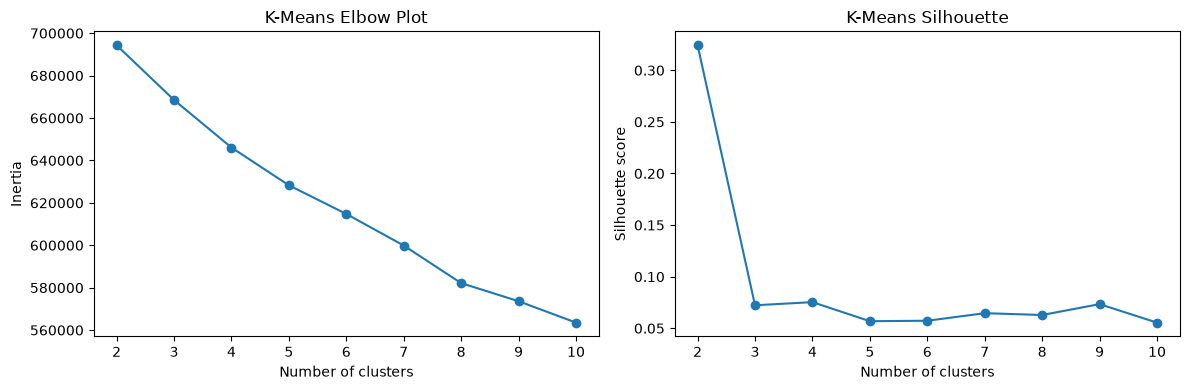

In [4]:
k_values = range(2, 11)
inertias = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_train_scaled)
    inertias.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_train_scaled, labels, sample_size=1000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker='o')
axes[0].set(title='K-Means Elbow Plot', xlabel='Number of clusters', ylabel='Inertia')

axes[1].plot(k_values, silhouette_values, marker='o')
axes[1].set(title='K-Means Silhouette', xlabel='Number of clusters', ylabel='Silhouette score')
plt.tight_layout()
plt.show()


## Elbow Analysis

The elbow plot shows a clear initial reduction in inertia as the number of clusters increases from 2 to 4. The curve becomes less steep after about 4 or 5 clusters, so 4 or 5 is a reasonable elbow range. The elbow is not perfectly sharp, so the result should be treated as an approximate trade-off rather than a definitive cluster count.

The silhouette score has its maximum at **2 clusters** (approximately 0.32). It drops sharply when a third cluster is added and remains near 0.06-0.08 for 3 to 10 clusters. Therefore, based on cluster separation, **2 clusters is the strongest choice** and is consistent with the dataset's legitimate and phishing status classes.

Together, the plots suggest that **legitimate and phishing websites produce two broad feature patterns**, but the separation is weak: a silhouette score of approximately 0.32 is only moderate. The clusters are likely overlapping, and K-Means is finding broad groups rather than perfectly distinct phishing and legitimate populations.

Using more than 4 or 5 clusters continues to reduce inertia, but the small improvement in within-cluster distance does not produce substantially better separation. Thus, adding extra clusters would mainly divide existing groups into smaller, less distinct subgroups and increase model complexity. The 2-cluster model is therefore preferred for simplicity and alignment with the classification problem, although its cluster quality should be confirmed with test accuracy, confusion matrices, and cluster-to-class mapping.

In [5]:
best_k = k_values[int(np.argmax(silhouette_values))]
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_scaled)
test_clusters = kmeans.predict(X_test_scaled)

print('Selected K-Means clusters:', best_k)
print('Silhouette:', round(max(silhouette_values), 4))


Selected K-Means clusters: 2
Silhouette: 0.3243


In [6]:
# Use training labels only to give each cluster a class name for evaluation.
cluster_to_class = {}
for cluster in sorted(set(train_clusters)):
    cluster_to_class[cluster] = y_train.iloc[np.flatnonzero(train_clusters == cluster)].mode().iloc[0]

train_predictions = np.array([cluster_to_class[c] for c in train_clusters])
test_predictions = np.array([cluster_to_class[c] for c in test_clusters])

print('Cluster to class mapping:', cluster_to_class)
print('Training accuracy:', round(accuracy_score(y_train, train_predictions), 4))
print('Test accuracy:', round(accuracy_score(y_test, test_predictions), 4))
print('Adjusted Rand Index:', round(adjusted_rand_score(y_test, test_clusters), 4))
print('Confusion matrix\n', confusion_matrix(y_test, test_predictions))


Cluster to class mapping: {0: 0, 1: 1}
Training accuracy: 0.6166
Test accuracy: 0.6216
Adjusted Rand Index: 0.059
Confusion matrix
 [[1137    6]
 [ 859  284]]


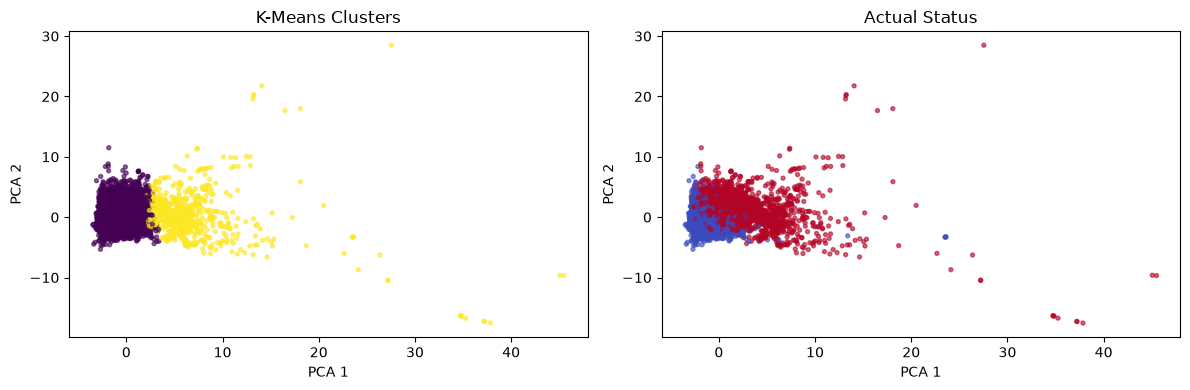

In [7]:
pca = PCA(n_components=2, random_state=42)
train_pca = pca.fit_transform(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(train_pca[:, 0], train_pca[:, 1], c=train_clusters, cmap='viridis', s=8, alpha=0.6)
axes[0].set(title='K-Means Clusters', xlabel='PCA 1', ylabel='PCA 2')

axes[1].scatter(train_pca[:, 0], train_pca[:, 1], c=y_train, cmap='coolwarm', s=8, alpha=0.6)
axes[1].set(title='Actual Status', xlabel='PCA 1', ylabel='PCA 2')
plt.tight_layout()
plt.show()


## KMeans Clustering Analysis

I applied K-Means clustering to the standardized phishing website features and projected the training results into two principal components for visualization. PCA 1 and PCA 2 allowed me to view the high-dimensional clustering patterns on a 2D plot. The left panel shows the cluster assignment identified by K-Means, while the right panel displays the known website status for comparison.

In the cluster plot, K-Means divided the websites into two broad groups: a dense purple cluster near the lower PCA 1 values and a yellow cluster that extends toward higher PCA 1 values. This separation is influenced primarily by PCA 1. PCA 2 shows some vertical variation, but it does not create a clear boundary between the groups.

When I compared these discovered groups with the actual legitimate and phishing statuses, I found substantial overlap. Many legitimate and phishing websites are mixed within the dense central area, and the yellow cluster contains a mixture of both statuses. This indicates that K-Means identified geometric patterns in the feature space, but the clusters do not automatically correspond perfectly to the true phishing and legitimate classes.

I also observed several points far from the dense region in the positive PCA 1 direction. These points represent websites whose feature combinations are different from most observations. They may be unusual website patterns or outlying feature values, but they cannot be considered phishing solely based on their position in the plot.

Overall, I conclude that 2-cluster K-Means provides useful descriptive insight into broad website feature patterns, but it is not a definitive phishing detection model. The overlap shown in the PCA plot is consistent with the moderate silhouette score and should be confirmed with cluster-to-class accuracy and the confusion matrix. K-Means is therefore useful for understanding the structure of the data, while supervised classification would be more appropriate for making reliable phishing predictions.

## DBSCAN


DBSCAN groups dense regions and marks isolated points as noise. We compare a few epsilon values and minimum-neighbor settings, then evaluate the selected model on the held-out test set.


In [8]:
eps_values = [1.5, 2.0, 2.5, 3.0]
min_samples_values = [5, 10, 20]
dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_train_scaled)
        non_noise = labels != -1
        cluster_count = len(set(labels[non_noise]))
        coverage = non_noise.mean()
        if cluster_count >= 2:
            score = silhouette_score(X_train_scaled[non_noise], labels[non_noise], sample_size=1000, random_state=42)
        else:
            score = -1
        dbscan_results.append((score, coverage, eps, min_samples))

valid_results = [row for row in dbscan_results if row[1] > 0.5]
if valid_results:
    _, _, best_eps, best_min_samples = max(valid_results)
else:
    _, _, best_eps, best_min_samples = max(dbscan_results)

print('Selected DBSCAN eps:', best_eps)
print('Selected DBSCAN min_samples:', best_min_samples)


Selected DBSCAN eps: 1.5
Selected DBSCAN min_samples: 20


In [9]:
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
train_clusters_db = dbscan.fit_predict(X_train_scaled)
core_neighbors = NearestNeighbors(n_neighbors=1).fit(X_train_scaled[dbscan.core_sample_indices_])
core_labels = train_clusters_db[dbscan.core_sample_indices_]

distances, indices = core_neighbors.kneighbors(X_test_scaled)
test_clusters_db = np.array([
    core_labels[index] if distance <= best_eps else -1
    for distance, index in zip(distances[:, 0], indices[:, 0])
])

print('Training clusters (excluding noise):', sorted(set(train_clusters_db) - {-1}))
print('Training noise percent:', round(np.mean(train_clusters_db == -1) * 100, 2))
print('Test noise percent:', round(np.mean(test_clusters_db == -1) * 100, 2))


Training clusters (excluding noise): [0, 1, 2, 3, 4, 5]
Training noise percent: 97.44
Test noise percent: 97.38


In [10]:
# Map each non-noise training cluster to a class using training labels only.
db_cluster_to_class = {}
for cluster in sorted(set(train_clusters_db) - {-1}):
    cluster_to_class_rows = y_train.iloc[np.flatnonzero(train_clusters_db == cluster)]
    db_cluster_to_class[cluster] = cluster_to_class_rows.mode().iloc[0]

train_db_predictions = np.array([
    db_cluster_to_class.get(cluster, y_train.mode().iloc[0]) for cluster in train_clusters_db
])
test_db_predictions = np.array([
    db_cluster_to_class.get(cluster, y_train.mode().iloc[0]) for cluster in test_clusters_db
])

print('DBSCAN cluster to class mapping:', db_cluster_to_class)
print('Training accuracy:', round(accuracy_score(y_train, train_db_predictions), 4))
print('Test accuracy:', round(accuracy_score(y_test, test_db_predictions), 4))
print('Confusion matrix\n', confusion_matrix(y_test, test_db_predictions))


DBSCAN cluster to class mapping:

 {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
Training accuracy: 0.5256
Test accuracy: 0.5262
Confusion matrix
 [[1143    0]
 [1083   60]]


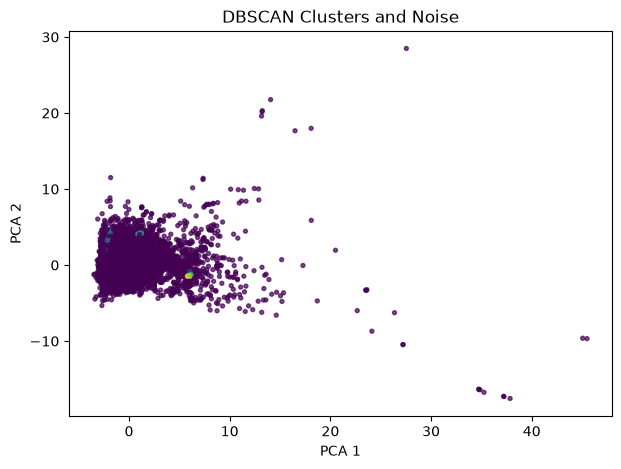

In [11]:
train_pca_db = PCA(n_components=2, random_state=42).fit_transform(X_train_scaled)
plt.figure(figsize=(7, 5))
plt.scatter(train_pca_db[:, 0], train_pca_db[:, 1], c=train_clusters_db, cmap='viridis', s=8, alpha=0.7)
plt.title('DBSCAN Clusters and Noise')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()


## Conclusion from DBSCAN on the Phishing Website dataset

Based on the above grpah my observation is that it is identifying a single, dense region where most websites overlap. This made clear separation difficult. A few points extend toward the right and lower areas, looking more like scattered outliers than meaningful clusters.

The graph suggests that DBSCAN found density patterns rather than distinct phishing classes. The colors show cluster assignments, not legitimacy or phishing directly. Overall, the structure appears weak and tightly overlapping. SIne I have used the same dataset with other techniques and it identifies the two site types(phishing non phishing)so most likely its due to higher dimensionality where DBSCAN is known  not to perform . We will try DBSCAN  with a reduced feature set with PCA and see how it performs


## Hierarchical Agglomerative Clustering


Hierarchical clustering repeatedly merges the closest groups. Ward linkage is used to create two clusters, and the dendrogram below uses a small sample for readability.


In [12]:
hac = AgglomerativeClustering(n_clusters=2, linkage='ward')
train_clusters_hac = hac.fit_predict(X_train_scaled)

# Assign test points to the nearest HAC training-cluster centroid.
hac_centroids = np.array([
    X_train_scaled[train_clusters_hac == cluster].mean(axis=0)
    for cluster in sorted(set(train_clusters_hac))
])
hac_neighbors = NearestNeighbors(n_neighbors=1).fit(hac_centroids)
_, hac_test_indices = hac_neighbors.kneighbors(X_test_scaled)
test_clusters_hac = hac_test_indices[:, 0]

hac_cluster_to_class = {}
for cluster in sorted(set(train_clusters_hac)):
    hac_cluster_to_class[cluster] = y_train.iloc[np.flatnonzero(train_clusters_hac == cluster)].mode().iloc[0]

train_hac_predictions = np.array([hac_cluster_to_class[c] for c in train_clusters_hac])
test_hac_predictions = np.array([hac_cluster_to_class[c] for c in test_clusters_hac])

print('Training accuracy:', round(accuracy_score(y_train, train_hac_predictions), 4))
print('Test accuracy:', round(accuracy_score(y_test, test_hac_predictions), 4))
print('Adjusted Rand Index:', round(adjusted_rand_score(y_test, test_clusters_hac), 4))
print('Confusion matrix\n', confusion_matrix(y_test, test_hac_predictions))


Training accuracy: 0.6017
Test accuracy: 0.6234
Adjusted Rand Index: 0.0607
Confusion matrix
 [[1135    8]
 [ 853  290]]


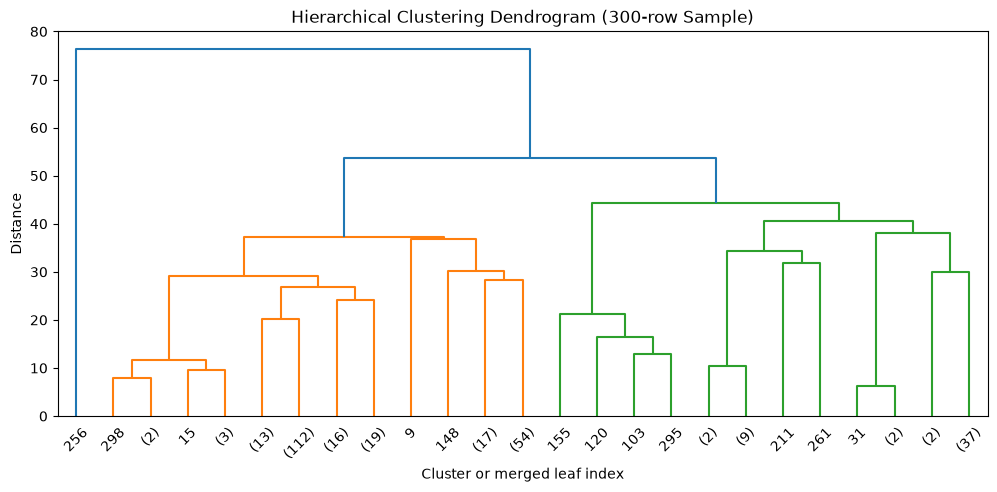

In [13]:
sample_size = min(300, len(X_train_scaled))
sample_indices = np.random.default_rng(42).choice(
    len(X_train_scaled), sample_size, replace=False
)
sample = X_train_scaled[sample_indices]
linked = linkage(sample, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode='level', p=5)
plt.title('Hierarchical Clustering Dendrogram (300-row Sample)')
plt.xlabel('Cluster or merged leaf index')
plt.ylabel('Distance')
plt.show()


In [14]:
# Check the label for the sample displayed with leaf index 256.
leaf_index = 256
train_row_index = sample_indices[leaf_index]
status_value = int(y_train.iloc[train_row_index])
status_label = 'phishing' if status_value == 1 else 'legitimate'

print('Dendrogram leaf index:', leaf_index)
print('Training row position:', train_row_index)
print('Status value:', status_value)
print('Website category:', status_label)


Dendrogram leaf index: 256
Training row position: 813
Status value: 1
Website category: phishing


## Conclusion from the above Dendrogram

I observed that the dendrogram describes how the 300 sampled websites were grouped by their standardized feature similarities. At the lowest levels, nearby websites merged at small distances. As the vertical distance increased, the merges became broader and more meaningful , at a distance of above 65 we see it has basically twp clusters . Since the 256th index leaf is phishing that would mean the other i.e the one on the right is non phishing site based on high level grouping, the dendrogram itself does not determine a single correct number of clusters. My two-cluster HAC model is only one possible interpretation.

Compare the test accuracies and confusion matrices above. The cluster-to-class mappings are learned only from the training set. K-Means and HAC use every point, while DBSCAN may identify some test points as noise rather than assigning them to a cluster. These results show whether unsupervised groups align with the phishing and legitimate labels.


## Performance with Reduced Features (PCA)

The code below retains enough principal components to explain at least 95% of the training variance. It then reruns the three clustering methods and compares their test accuracy with the original-feature models.


PCA features: 60
Variance retained: 0.9512


DBSCAN PCA eps: 1.0
PCA DBSCAN noise percent: 94.97


,Method,Original accuracy,PCA accuracy,Original silhouette,PCA silhouette,PCA ARI
0,K-Means,0.6216,0.6216,0.3349,0.3378,0.0590
1,DBSCAN,0.5262,0.5424,0.7415,0.6952,0.0028
2,HAC,0.6234,0.6172,0.3381,0.3661,0.0548


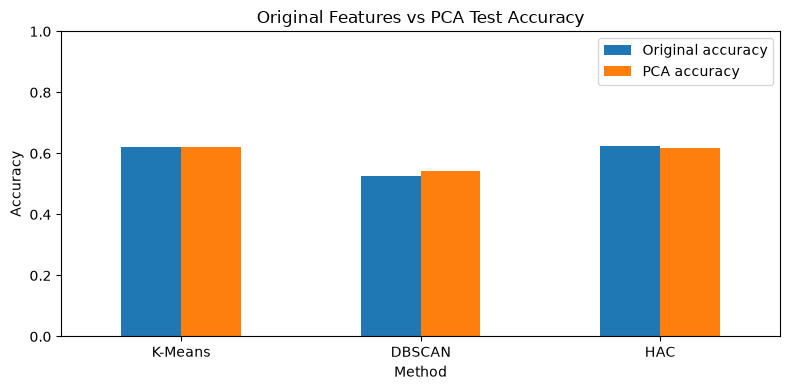

In [15]:
pca_reduced = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_reduced.fit_transform(X_train_scaled)
X_test_pca = pca_reduced.transform(X_test_scaled)

print('PCA features:', X_train_pca.shape[1])
print('Variance retained:', round(pca_reduced.explained_variance_ratio_.sum(), 4))

# K-Means with the same selected cluster count.
kmeans_pca = KMeans(n_clusters=best_k, random_state=42, n_init=10)
train_km_pca = kmeans_pca.fit_predict(X_train_pca)
test_km_pca = kmeans_pca.predict(X_test_pca)

km_mapping_pca = {}
for cluster in sorted(set(train_km_pca)):
    km_mapping_pca[cluster] = y_train.iloc[np.flatnonzero(train_km_pca == cluster)].mode().iloc[0]

test_km_pca_predictions = np.array([km_mapping_pca[c] for c in test_km_pca])

# DBSCAN: tune eps and keep at least 50% coverage.
dbscan_pca_results = []
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_train_pca)
    covered = labels != -1
    cluster_count = len(set(labels[covered]))
    if cluster_count >= 2:
        score = silhouette_score(X_train_pca[covered], labels[covered])
    else:
        score = -1
    dbscan_pca_results.append((score, covered.mean(), eps))

valid_pca_dbscan = [row for row in dbscan_pca_results if row[1] >= 0.50]
best_pca_dbscan = max(valid_pca_dbscan or dbscan_pca_results)
pca_db_eps = best_pca_dbscan[2]

dbscan_pca = DBSCAN(eps=pca_db_eps, min_samples=10)
train_db_pca = dbscan_pca.fit_predict(X_train_pca)
core_mask = np.zeros(len(X_train_pca), dtype=bool)
core_mask[dbscan_pca.core_sample_indices_] = True

if core_mask.any():
    db_neighbors = NearestNeighbors(n_neighbors=1).fit(X_train_pca[core_mask])
    core_labels = train_db_pca[core_mask]
    distances, indices = db_neighbors.kneighbors(X_test_pca)
    test_db_pca = np.array([
        core_labels[index] if distance <= pca_db_eps else -1
        for distance, index in zip(distances[:, 0], indices[:, 0])
    ])
else:
    test_db_pca = np.full(len(X_test_pca), -1)

db_mapping_pca = {}
for cluster in sorted(set(train_db_pca) - {-1}):
    db_mapping_pca[cluster] = y_train.iloc[np.flatnonzero(train_db_pca == cluster)].mode().iloc[0]

test_db_pca_predictions = np.array([
    db_mapping_pca.get(cluster, y_train.mode().iloc[0]) for cluster in test_db_pca
])

# Hierarchical clustering with two groups.
hac_pca = AgglomerativeClustering(n_clusters=2, linkage='ward')
train_hac_pca = hac_pca.fit_predict(X_train_pca)

hac_centroids_pca = np.array([
    X_train_pca[train_hac_pca == cluster].mean(axis=0)
    for cluster in sorted(set(train_hac_pca))
])
hac_neighbors_pca = NearestNeighbors(n_neighbors=1).fit(hac_centroids_pca)
_, hac_test_indices_pca = hac_neighbors_pca.kneighbors(X_test_pca)
test_hac_pca = hac_test_indices_pca[:, 0]

hac_mapping_pca = {}
for cluster in sorted(set(train_hac_pca)):
    hac_mapping_pca[cluster] = y_train.iloc[np.flatnonzero(train_hac_pca == cluster)].mode().iloc[0]

test_hac_pca_predictions = np.array([hac_mapping_pca[c] for c in test_hac_pca])

original_km_silhouette = silhouette_score(X_train_scaled, train_clusters)
original_hac_silhouette = silhouette_score(X_train_scaled, train_clusters_hac)
original_db_covered = train_clusters_db != -1
original_db_silhouette = silhouette_score(
    X_train_scaled[original_db_covered], train_clusters_db[original_db_covered]
) if len(set(train_clusters_db[original_db_covered])) >= 2 else np.nan

pca_km_silhouette = silhouette_score(X_train_pca, train_km_pca)
pca_hac_silhouette = silhouette_score(X_train_pca, train_hac_pca)
pca_db_covered = train_db_pca != -1
pca_db_silhouette = silhouette_score(
    X_train_pca[pca_db_covered], train_db_pca[pca_db_covered]
) if len(set(train_db_pca[pca_db_covered])) >= 2 else np.nan

comparison = pd.DataFrame([
    {
        'Method': 'K-Means',
        'Original accuracy': accuracy_score(y_test, test_predictions),
        'PCA accuracy': accuracy_score(y_test, test_km_pca_predictions),
        'Original silhouette': original_km_silhouette,
        'PCA silhouette': pca_km_silhouette,
        'PCA ARI': adjusted_rand_score(y_test, test_km_pca),
    },
    {
        'Method': 'DBSCAN',
        'Original accuracy': accuracy_score(y_test, test_db_predictions),
        'PCA accuracy': accuracy_score(y_test, test_db_pca_predictions),
        'Original silhouette': original_db_silhouette,
        'PCA silhouette': pca_db_silhouette,
        'PCA ARI': adjusted_rand_score(y_test, test_db_pca),
    },
    {
        'Method': 'HAC',
        'Original accuracy': accuracy_score(y_test, test_hac_predictions),
        'PCA accuracy': accuracy_score(y_test, test_hac_pca_predictions),
        'Original silhouette': original_hac_silhouette,
        'PCA silhouette': pca_hac_silhouette,
        'PCA ARI': adjusted_rand_score(y_test, test_hac_pca),
    },
])
comparison.iloc[:, 1:] = comparison.iloc[:, 1:].round(4)
print('DBSCAN PCA eps:', pca_db_eps)
print('PCA DBSCAN noise percent:', round(np.mean(test_db_pca == -1) * 100, 2))
display(comparison)

comparison.set_index('Method')[['Original accuracy', 'PCA accuracy']].plot(
    kind='bar', figsize=(8, 4), rot=0
)
plt.title('Original Features vs PCA Test Accuracy')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## Curse of Dimensionality

In high dimensions, pairwise distances become more similar. As a result, nearest and farthest points are harder to distinguish, which is a reason clustering and distance-based methods can benefit from PCA. The plot below uses standardized training data projected to increasing numbers of principal components.


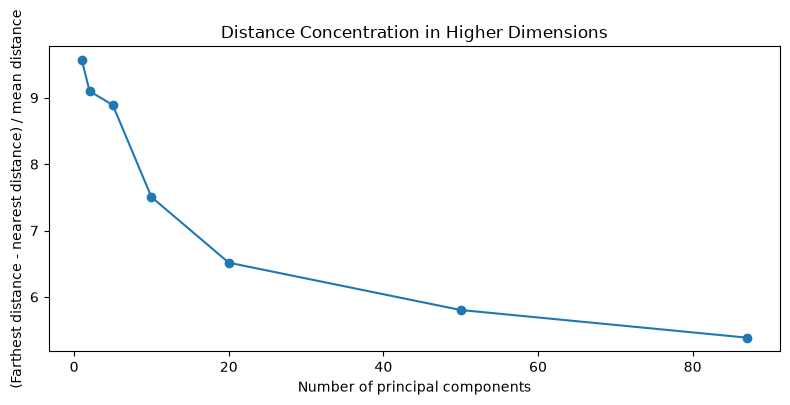

A lower relative spread in higher dimensions indicates that distances are concentrating and becoming less informative.


In [16]:
rng = np.random.default_rng(42)
full_pca = PCA(random_state=42).fit(X_train_scaled)
X_pca_full = full_pca.transform(X_train_scaled)
sample_rows = rng.choice(len(X_pca_full), size=min(1000, len(X_pca_full)), replace=False)
points = X_pca_full[sample_rows]

dimensions = [1, 2, 5, 10, 20, 50, points.shape[1]]
concentration = []

for d in sorted(set(dimensions)):
    distances = np.sqrt(np.sum(points[:, :d] ** 2, axis=1))
    relative_spread = (distances.max() - distances.min()) / distances.mean()
    concentration.append(relative_spread)

plt.figure(figsize=(8, 4))
plt.plot(sorted(set(dimensions)), concentration, marker='o')
plt.title('Distance Concentration in Higher Dimensions')
plt.xlabel('Number of principal components')
plt.ylabel('(Farthest distance - nearest distance) / mean distance')
plt.tight_layout()
plt.show()

print('A lower relative spread in higher dimensions indicates that distances are concentrating and becoming less informative.')


In [38]:
from IPython.display import Markdown, display

pca_component_count = X_train_pca.shape[1]
pca_variance_retained = pca_reduced.explained_variance_ratio_.sum()

km_row = comparison[comparison['Method'] == 'K-Means'].iloc[0]
db_row = comparison[comparison['Method'] == 'DBSCAN'].iloc[0]
hac_row = comparison[comparison['Method'] == 'HAC'].iloc[0]

print('PCA component count:', pca_component_count)
print('PCA variance retained:', f'{pca_variance_retained:.4f}', f"({pca_variance_retained:.2%})")
print('K-Means original/PCA accuracy:',
      f'{km_row["Original accuracy"]:.4f}', '/', f'{km_row["PCA accuracy"]:.4f}')
print('DBSCAN original/PCA accuracy:',
      f'{db_row["Original accuracy"]:.4f}', '/', f'{db_row["PCA accuracy"]:.4f}')
print('HAC original/PCA accuracy:',
      f'{hac_row["Original accuracy"]:.4f}', '/', f'{hac_row["PCA accuracy"]:.4f}')



PCA component count: 60
PCA variance retained: 0.9512 (95.12%)
K-Means original/PCA accuracy: 0.6216 / 0.6216
DBSCAN original/PCA accuracy: 0.5262 / 0.5424
HAC original/PCA accuracy: 0.6234 / 0.6172


## Measured PCA Conclusion
PCA retained 60 components, explaining 95.12% of the training variance. The comparison shows mixed evidence: K-Means test accuracy changed from 62.16% to 62.16%; DBSCAN changed from 52.62% to 54.24%; and HAC changed from 62.34% to 61.72%.

Therefore, PCA does not guarantee better clustering. Its value must be measured for each method. PCA mainly reduces redundant dimensions and can improve a distance-based method when noise and correlated features are removed. The comparison supports using PCA experimentally rather than assuming that every clustering result will improve.

## Second DBSCAN Round Using PCA Features

The first PCA-based DBSCAN search used only five epsilon values and produced too little coverage. This second round performs a finer grid search using the PCA features, compares both epsilon and minimum-neighbor settings, and requires at least 70% of training rows to belong to clusters.\n

In [18]:
eps_values_pca = np.arange(0.5, 5.1, 0.5)
min_samples_pca = [5, 10, 15, 20, 30]
pca_dbscan_search = []

for eps in eps_values_pca:
    for min_samples in min_samples_pca:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_train_pca)
        covered = labels != -1
        coverage = covered.mean()
        cluster_count = len(set(labels[covered]))

        if coverage >= 0.70 and cluster_count >= 2:
            score = silhouette_score(
                X_train_pca[covered], labels[covered],
                sample_size=1000, random_state=42
            )
        else:
            score = np.nan

        pca_dbscan_search.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': cluster_count,
            'coverage': coverage,
            'silhouette': score,
        })

pca_dbscan_results = pd.DataFrame(pca_dbscan_search)
valid_pca_dbscan_results = pca_dbscan_results.dropna(subset=['silhouette'])
valid_pca_dbscan_results = valid_pca_dbscan_results.sort_values(
    ['silhouette', 'coverage'], ascending=[False, False]
)

display(valid_pca_dbscan_results.head(10).round(4))

if not valid_pca_dbscan_results.empty:
    best_pca_dbscan_row = valid_pca_dbscan_results.iloc[0]
    best_pca_eps = float(best_pca_dbscan_row['eps'])
    best_pca_min_samples = int(best_pca_dbscan_row['min_samples'])
else:
    best_pca_eps = 3.0
    best_pca_min_samples = 10

print('Second-round PCA DBSCAN eps:', best_pca_eps)
print('Second-round PCA DBSCAN min_samples:', best_pca_min_samples)


,eps,min_samples,clusters,coverage,silhouette
49,5.0,30,3,0.7220,0.2319
48,5.0,20,10,0.7642,0.2172
46,5.0,10,20,0.8002,0.1917
41,4.5,10,21,0.7293,0.1916
47,5.0,15,15,0.7799,0.1760
45,5.0,5,49,0.8436,0.0918
40,4.5,5,68,0.7847,0.0494


Second-round PCA DBSCAN eps: 5.0
Second-round PCA DBSCAN min_samples: 30


Training coverage: 0.722
Training noise percent: 27.8
Training clusters: 3
Training silhouette: 0.237
Training accuracy: 0.5351
Test accuracy: 0.5363
Test noise percent: 28.52
Cluster-to-class mapping: {0: 0, 1: 1, 2: 1}
Confusion matrix
 [[1143    0]
 [1060   83]]


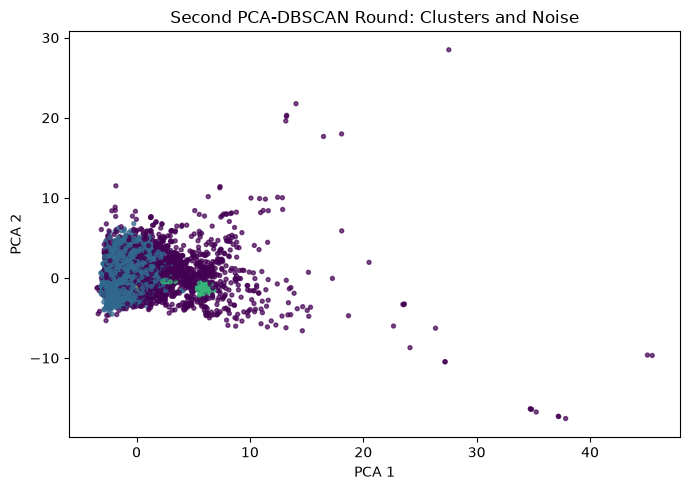

In [19]:
dbscan_pca_round2 = DBSCAN(
    eps=best_pca_eps,
    min_samples=best_pca_min_samples
)
train_db_pca_round2 = dbscan_pca_round2.fit_predict(X_train_pca)

core_mask_round2 = np.zeros(len(X_train_pca), dtype=bool)
core_mask_round2[dbscan_pca_round2.core_sample_indices_] = True

if core_mask_round2.any():
    round2_neighbors = NearestNeighbors(n_neighbors=1).fit(
        X_train_pca[core_mask_round2]
    )
    round2_core_labels = train_db_pca_round2[core_mask_round2]
    round2_distances, round2_indices = round2_neighbors.kneighbors(X_test_pca)
    test_db_pca_round2 = np.array([
        round2_core_labels[index] if distance <= best_pca_eps else -1
        for distance, index in zip(round2_distances[:, 0], round2_indices[:, 0])
    ])
else:
    test_db_pca_round2 = np.full(len(X_test_pca), -1)

round2_mapping = {}
for cluster in sorted(set(train_db_pca_round2) - {-1}):
    cluster_labels = y_train.iloc[np.flatnonzero(train_db_pca_round2 == cluster)]
    round2_mapping[cluster] = cluster_labels.mode().iloc[0]

train_round2_predictions = np.array([
    round2_mapping.get(cluster, y_train.mode().iloc[0])
    for cluster in train_db_pca_round2
])
test_round2_predictions = np.array([
    round2_mapping.get(cluster, y_train.mode().iloc[0])
    for cluster in test_db_pca_round2
])

train_covered_round2 = train_db_pca_round2 != -1
cluster_count_round2 = len(set(train_db_pca_round2[train_covered_round2]))
if cluster_count_round2 >= 2:
    silhouette_round2 = silhouette_score(
        X_train_pca[train_covered_round2],
        train_db_pca_round2[train_covered_round2]
    )
else:
    silhouette_round2 = np.nan

print('Training coverage:', round(train_covered_round2.mean(), 4))
print('Training noise percent:', round((1 - train_covered_round2.mean()) * 100, 2))
print('Training clusters:', cluster_count_round2)
print('Training silhouette:', round(silhouette_round2, 4))
print('Training accuracy:', round(accuracy_score(y_train, train_round2_predictions), 4))
print('Test accuracy:', round(accuracy_score(y_test, test_round2_predictions), 4))
print('Test noise percent:', round(np.mean(test_db_pca_round2 == -1) * 100, 2))
print('Cluster-to-class mapping:', round2_mapping)
print('Confusion matrix\n', confusion_matrix(y_test, test_round2_predictions))

plot_round2_pca = PCA(n_components=2, random_state=42).fit_transform(X_train_pca)
plt.figure(figsize=(7, 5))
plt.scatter(
    plot_round2_pca[:, 0], plot_round2_pca[:, 1],
    c=train_db_pca_round2, cmap='viridis', s=8, alpha=0.7
)
plt.title('Second PCA-DBSCAN Round: Clusters and Noise')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.tight_layout()
plt.show()


## conclussion
For the dataset that I am using and the purpose these three techniques perfrom the worst and primarily due to curse of dimensionality. We see that DBSCAN in particular was the worst effected. It improved a bit whern I did PCA and reduced the features (highest silhoutte score had three clusters but we know we  had only two clusters so must be that it had lot of overlapped once which it created as another cluster). So this could be used in other cases where the number of features are much lesser. For this Phishing website dataset if we reduce the features to 5-6 we may get better ersult but we will lose lot of information and thus I feel this is not the right fit
